# Od DN k odrazivosti: Landsat 8 nad Brnem

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/dn_to_reflectance_brno_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Od DN k odrazivosti](https://openskylab.space/edu_viz_dn_to_reflectance.html) · [English version](dn_to_reflectance_brno_en.ipynb)

Vizuál prochází řetězec od digitálního čísla přes zář k odrazivosti nad atmosférou (TOA) a na povrchu (BOA) a ukazuje, co opraví metoda tmavého objektu (DOS) a empirická přímka. Tady celý řetězec spočítáš na dvou skutečných snímcích Landsatu 8 nad Brnem a výsledek porovnáš s odrazivostí Sentinelu-2 L2A z téhož týdne.

**Cíl:** převést DN na zář a odrazivost TOA, ukázat, proč DN ze dvou dnů nejsou srovnatelná, změřit vliv atmosféry na vodě a porovnat korekci DOS a empirickou přímku s odrazivostí na povrchu.

**Data:** Landsat 8 OLI Collection 1 Level-1 z veřejného archivu Google Cloud: `LC08_L1TP_190026_20200808_20200821_01_T1` (8. 8. 2020, výška Slunce 54°) a `LC08_L1TP_190026_20190227_20190309_01_T1` (27. 2. 2019, výška Slunce 30°), pásma B1–B7, BQA a MTL. Pro srovnání Sentinel-2 L2A `S2B_33UXQ_20200808_0_L2A` (8. 8. 2020) z Earth Search. Výřez 12 × 12 km od Brněnské přehrady k centru Brna, asi 25 MB.

**Úkoly:** pět. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 45 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava a data

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import reproject, Resampling

GCS = "https://storage.googleapis.com/gcp-public-data-landsat/LC08/01/190/026/"
SCENES = {"léto": "LC08_L1TP_190026_20200808_20200821_01_T1", "zima": "LC08_L1TP_190026_20190227_20190309_01_T1"}
X0, Y0, SIZE = 607620, 5446530, 12000          # levý dolní roh výřezu v UTM 33N (m) a jeho strana
BANDS = {1: "pobřežní 443", 2: "modrá 482", 3: "zelená 561", 4: "červená 655", 5: "NIR 865", 6: "SWIR1 1609", 7: "SWIR2 2201"}

def mtl(scene):
    txt = requests.get(f"{GCS}{scene}/{scene}_MTL.txt", timeout=60).text
    return {k.strip(): v.strip().strip('"') for k, v in (l.split(" = ") for l in txt.splitlines() if " = " in l)}

def read(scene, band):
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2):
        with rasterio.open(f"/vsicurl/{GCS}{scene}/{scene}_{band}.TIF") as r:
            w = rasterio.windows.from_bounds(X0, Y0, X0 + SIZE, Y0 + SIZE, r.transform).round_offsets().round_lengths()
            read.transform = r.window_transform(w)
            return r.read(1, window=w).astype(float)

L8 = {}
for season, scene in SCENES.items():
    meta = mtl(scene)
    dn = {b: read(scene, f"B{b}") for b in BANDS}
    L8_transform = read.transform
    qa = read(scene, "BQA").astype(int)
    ok = ((qa >> 4) & 1 == 0) & ((qa >> 7) & 3 < 3) & (dn[1] > 0)     # bez mraků a jistých stínů
    L8[season] = {"meta": meta, "dn": dn, "ok": ok, "transform": L8_transform}
    print(f"{season}: {scene}, výška Slunce {float(meta['SUN_ELEVATION']):.1f}°, vzdálenost Země–Slunce {meta['EARTH_SUN_DISTANCE']} AU, jasné pixely {ok.mean():.1%}")

léto: LC08_L1TP_190026_20200808_20200821_01_T1, výška Slunce 53.7°, vzdálenost Země–Slunce 1.0139144 AU, jasné pixely 100.0%


zima: LC08_L1TP_190026_20190227_20190309_01_T1, výška Slunce 29.9°, vzdálenost Země–Slunce 0.9902866 AU, jasné pixely 99.9%


## 2. Z DN na zář a odrazivost TOA

Zář: L = M_L · DN + A_L. Odrazivost TOA: ρ = (M_ρ · DN + A_ρ) / sin(výška Slunce). Koeficienty jsou v souboru MTL; v M_ρ je už započtena vzdálenost Země–Slunce i sluneční ozáření pásma.

In [3]:
for s in L8.values():
    m, dn = s["meta"], s["dn"]
    sun = np.sin(np.radians(float(m["SUN_ELEVATION"])))
    s["rad"] = {b: float(m[f"RADIANCE_MULT_BAND_{b}"]) * dn[b] + float(m[f"RADIANCE_ADD_BAND_{b}"]) for b in BANDS}
    s["toa"] = {b: (float(m[f"REFLECTANCE_MULT_BAND_{b}"]) * dn[b] + float(m[f"REFLECTANCE_ADD_BAND_{b}"])) / sun for b in BANDS}

rows = []
for b, name in BANDS.items():
    r = {"pásmo": f"B{b} {name}"}
    for season, s in L8.items():
        ok = s["ok"]
        r[f"DN {season}"] = np.median(s["dn"][b][ok])
        r[f"zář {season}"] = np.median(s["rad"][b][ok])
        r[f"ρ TOA {season}"] = np.median(s["toa"][b][ok])
    rows.append(r)
tab = pd.DataFrame(rows).set_index("pásmo")
tab["poměr DN léto/zima"] = tab["DN léto"] / tab["DN zima"]
tab["poměr ρ léto/zima"] = tab["ρ TOA léto"] / tab["ρ TOA zima"]
tab.round(3)

,DN léto,zář léto,ρ TOA léto,DN zima,zář zima,ρ TOA zima,poměr DN léto/zima,poměr ρ léto/zima
pásmo,,,,,,,,
B1 pobřežní 443,10110.0,62.416,0.127,8525.0,45.129,0.141,1.186,0.898
B2 modrá 482,9236.0,52.981,0.105,7925.0,38.351,0.117,1.165,0.897
B3 zelená 561,8688.0,42.505,0.092,7312.0,27.929,0.093,1.188,0.988
B4 červená 655,7969.0,28.854,0.074,7227.0,22.690,0.089,1.103,0.826
B5 NIR 865,16088.0,65.943,0.275,8918.0,24.426,0.157,1.804,1.753
B6 SWIR1 1609,11763.0,10.002,0.168,9170.0,6.465,0.167,1.283,1.004
B7 SWIR2 2201,8769.0,1.879,0.094,7986.0,1.560,0.120,1.098,0.782


> **✏️ Úkol 1.** O kolik se mediány DN mezi létem a zimou liší a o kolik mediány odrazivosti TOA? Kolik z rozdílu DN vysvětlí jen výška Slunce (porovnej poměr sinů výšek)? Proč se ani odrazivost TOA mezi daty úplně neshoduje (stav porostu, případný sníh, atmosféra)?

*Tvoje odpověď:* 

## 3. Odrazivost na povrchu ze Sentinelu-2 jako reference

Sentinel-2 L2A z 8. 8. 2020 (týž den) má odrazivost BOA z modelu Sen2Cor. Převzorkujeme ho na mřížku Landsatu (průměr do pixelu 30 m) a přiřadíme si pásma s podobnou vlnovou délkou. Dokonalou shodu nečekej: jde o jiný senzor s trochu jinými pásmy, snímek pořízený asi o 20 minut později a z jiného úhlu pohledu.

pixelů pro srovnání: 152473


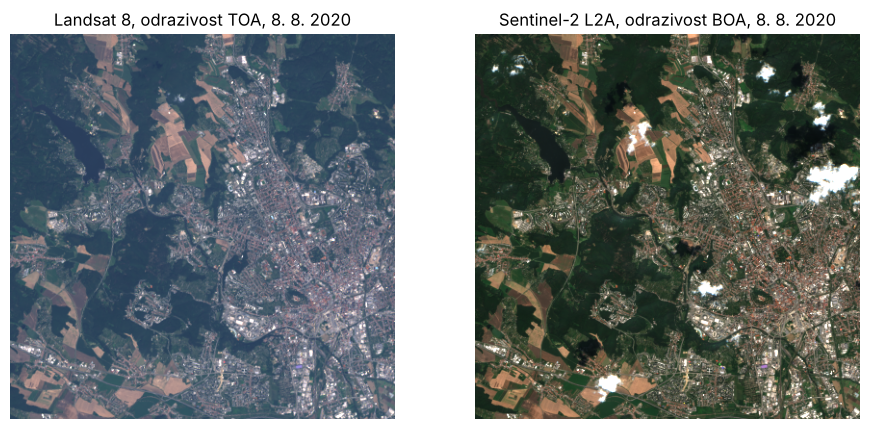

In [4]:
item = requests.get("https://earth-search.aws.element84.com/v1/collections/sentinel-2-l2a/items/S2B_33UXQ_20200808_0_L2A", timeout=60).json()
PAIR = {1: "coastal", 2: "blue", 3: "green", 4: "red", 5: "nir08", 6: "swir16", 7: "swir22"}
shape = L8["léto"]["dn"][1].shape
grid = L8["léto"]["transform"]
def s2(key, res=Resampling.average):
    out = np.zeros(shape, np.float32)
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2):
        with rasterio.open("/vsicurl/" + item["assets"][key]["href"]) as r:
            reproject(rasterio.band(r, 1), out, dst_transform=grid, dst_crs="EPSG:32633", resampling=res)
    return out
p = item["properties"]   # od základní linie zpracování 04.00 mají DN posun +1000, pokud ho katalog ještě neodečetl
off = -1000 if float(p.get("s2:processing_baseline", "0")) >= 4 and not p.get("earthsearch:boa_offset_applied", False) else 0
boa = {b: (s2(k) + off) / 10000 for b, k in PAIR.items()}
scl = s2("scl", Resampling.mode)
summer = L8["léto"]
valid = summer["ok"] & np.isin(scl, [4, 5, 6]) & (boa[1] > 0)
print(f"pixelů pro srovnání: {valid.sum()}")
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
rgb = lambda d: np.clip(np.dstack([d[4], d[3], d[2]]) / 0.25, 0, 1)
ax[0].imshow(rgb(summer["toa"])); ax[0].set_title("Landsat 8, odrazivost TOA, 8. 8. 2020")
ax[1].imshow(rgb(boa)); ax[1].set_title("Sentinel-2 L2A, odrazivost BOA, 8. 8. 2020")
for a in ax: a.axis("off")
plt.show()

> **✏️ Úkol 2.** Porovnej oba obrázky se stejným roztažením barev. Proč působí snímek s odrazivostí TOA světleji, modřeji a méně kontrastně? Které povrchy se mezi TOA a BOA mění nejvíc, tmavé, nebo světlé? Vysvětli to aditivním příspěvkem atmosféry.

*Tvoje odpověď:* 

## 4. Modrá voda nad atmosférou

Brněnská přehrada a Svratka jsou v NIR skoro černé. Porovnáme jejich odrazivost TOA a BOA ve všech pásmech: rozdíl je hlavně světlo rozptýlené atmosférou (zář dráhy).

In [5]:
ndwi = (boa[3] - boa[5]) / (boa[3] + boa[5])
water = valid & (ndwi > 0.3) & (scl == 6)
w = pd.DataFrame({"ρ TOA (Landsat)": [np.median(summer["toa"][b][water]) for b in BANDS],
                  "ρ BOA (Sentinel-2)": [np.median(boa[b][water]) for b in BANDS]}, index=[f"B{b} {n}" for b, n in BANDS.items()])
w["TOA − BOA"] = w.iloc[:, 0] - w.iloc[:, 1]
print(f"vodních pixelů: {water.sum()}")
w.round(4)

vodních pixelů: 1134


,ρ TOA (Landsat),ρ BOA (Sentinel-2),TOA − BOA
B1 pobřežní 443,0.1166,0.0278,0.0888
B2 modrá 482,0.0910,0.0285,0.0625
B3 zelená 561,0.0617,0.0292,0.0325
B4 červená 655,0.0419,0.0202,0.0217
B5 NIR 865,0.0280,0.0108,0.0171
B6 SWIR1 1609,0.0066,0.0068,-0.0002
B7 SWIR2 2201,0.0036,0.0047,-0.0010


> **✏️ Úkol 3.** Jak se rozdíl TOA − BOA nad vodou mění s vlnovou délkou? Porovnej poměr mezi pásmy B1 a B4 s Rayleighovým zákonem (rozptyl ∝ λ⁻⁴). Proč je voda nad atmosférou modrá, i když je na povrchu tmavá ve všech pásmech?

*Tvoje odpověď:* 

## 5. Metoda tmavého objektu (DOS)

Předpokládáme, že nejtmavší pixely ve scéně mají na povrchu odrazivost skoro nulovou (běžně se bere 1 %, Chavez 1996). Co mají navíc, je zář dráhy, a tu odečteme od celé scény. DOS opraví jen aditivní část atmosféry.

In [6]:
pct = 0.1          # ◀ parametr: percentil, který považujeme za tmavý objekt (%)
rho_dark = 0.01    # ◀ parametr: předpokládaná skutečná odrazivost tmavého objektu
dos = {b: summer["toa"][b] - (np.percentile(summer["toa"][b][summer["ok"]], pct) - rho_dark) for b in BANDS}

def rmse(a, b, m=valid): return float(np.sqrt(np.mean((a[m] - b[m]) ** 2)))
def bias(a, b, m=valid): return float(np.mean(a[m] - b[m]))
res = pd.DataFrame({
    "tmavý objekt ρ TOA": [np.percentile(summer["toa"][b][summer["ok"]], pct) for b in BANDS],
    "RMSE TOA": [rmse(summer["toa"][b], boa[b]) for b in BANDS],
    "RMSE DOS": [rmse(dos[b], boa[b]) for b in BANDS],
    "bias DOS": [bias(dos[b], boa[b]) for b in BANDS],
}, index=[f"B{b}" for b in BANDS])
res.round(4)

,tmavý objekt ρ TOA,RMSE TOA,RMSE DOS,bias DOS
B1,0.1110,0.0805,0.0257,-0.0217
B2,0.0856,0.0534,0.0284,-0.0243
B3,0.0605,0.0245,0.0338,-0.0306
B4,0.0384,0.0196,0.0240,-0.0176
B5,0.0270,0.0289,0.0339,-0.0179
B6,0.0061,0.0276,0.0250,-0.0154
B7,0.0033,0.0328,0.0278,-0.0193


> **✏️ Úkol 4.** Ve kterých pásmech DOS chybu proti BOA zmenší a ve kterých ji naopak zvětší? Proč je bias DOS ve všech pásmech záporný (co DOS dělá s násobnou složkou, propustností atmosféry)? Nastav `pct = 2` a pak `rho_dark = 0`: co se stane? Kdy DOS selže úplně (zimní scéna se sněhem bez tmavých objektů, opar jen nad částí scény)?

*Tvoje odpověď:* 

## 6. Empirická přímka

V terénu se na snímek položí tmavý a světlý panel se změřenou odrazivostí. Tady jako panely poslouží tmavé a světlé pixely, jejichž odrazivost na povrchu známe ze Sentinelu-2. Pro každé pásmo proložíme přímku ρ_BOA = a · ρ_TOA + b: posun b souvisí se září dráhy a sklon s propustností atmosféry: pro ρ_TOA ≈ ρ_dráhy + T · ρ_BOA vychází a ≈ 1/T a b ≈ −ρ_dráhy/T.

       sklon a  posun b  RMSE TOA  RMSE DOS  RMSE emp. přímka
pásmo                                                        
B1      1.1242  -0.0574    0.0805    0.0257            0.0406
B2      1.6055  -0.1055    0.0534    0.0284            0.0188
B3      1.4626  -0.0586    0.0245    0.0338            0.0153
B4      1.3481  -0.0315    0.0196    0.0240            0.0178
B5      1.0733  -0.0132    0.0289    0.0339            0.0304
B6      1.1669   0.0122    0.0276    0.0250            0.0311
B7      1.3501   0.0303    0.0328    0.0278            0.0447


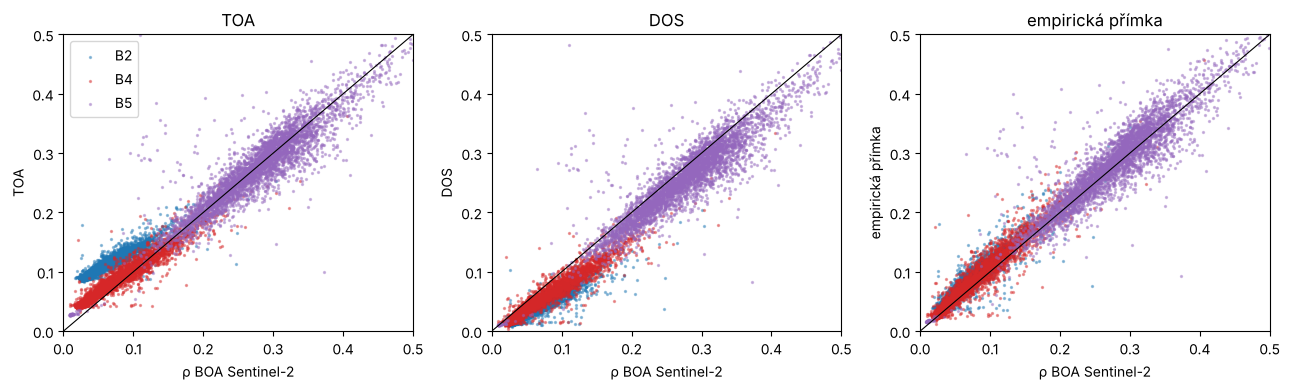

In [7]:
n_panel = 300        # ◀ parametr: kolik nejtmavších a nejsvětlejších pixelů použít jako panely
rng = np.random.default_rng(0)
el, rows = {}, []
for b in BANDS:
    v = np.flatnonzero(valid.ravel())
    order = v[np.argsort(boa[b].ravel()[v])]
    panels = np.r_[order[:n_panel], order[-n_panel:]]               # tmavé a světlé „panely“
    a, c = np.polyfit(summer["toa"][b].ravel()[panels], boa[b].ravel()[panels], 1)
    el[b] = a * summer["toa"][b] + c
    rows.append({"pásmo": f"B{b}", "sklon a": a, "posun b": c, "RMSE TOA": rmse(summer["toa"][b], boa[b]),
                 "RMSE DOS": rmse(dos[b], boa[b]), "RMSE emp. přímka": rmse(el[b], boa[b])})
print(pd.DataFrame(rows).set_index("pásmo").round(4))
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
sel = rng.choice(np.flatnonzero(valid.ravel()), 4000, replace=False)
for a_, (name, est) in zip(ax, [("TOA", summer["toa"]), ("DOS", dos), ("empirická přímka", el)]):
    for b, col in [(2, "tab:blue"), (4, "tab:red"), (5, "tab:purple")]:
        a_.scatter(boa[b].ravel()[sel], est[b].ravel()[sel], s=2, alpha=0.4, c=col, label=f"B{b}")
    a_.axline((0, 0), slope=1, color="k", lw=0.8); a_.set(xlim=(0, 0.5), ylim=(0, 0.5), xlabel="ρ BOA Sentinel-2", ylabel=name, title=name)
ax[0].legend(); plt.tight_layout(); plt.show()

> **✏️ Úkol 5.** Proč má empirická přímka v modrých pásmech záporný posun a sklon jiný než 1? Co fyzikálně vyjadřují? Která metoda dopadla nejlépe a proč DOS nemůže opravit sklon? Nastav `n_panel = 20`: co se stane se spolehlivostí přímky? Proč v terénu stačí dva panely, ale musí ležet ve stejném snímku a za stejného osvětlení?

*Tvoje odpověď:* 

> **✏️ Rozšíření (nepovinné).** Porovnej výsledky se spolužákem, který spustil notebook pro jiné místo: vyšel podobný rozdíl TOA − BOA nad vodou a podobný sklon empirické přímky? Čím se mohou lišit (jiný den, jiný opar, jiná výška Slunce)?

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Landsat 8 OLI Collection 1 Level-1, U.S. Geological Survey; veřejný archiv Google Cloud (`gcp-public-data-landsat`). Data USGS jsou bez omezení užití, s uvedením zdroje.
- USGS (2019). *Landsat 8 (L8) Data Users Handbook*, verze 5.0, kap. 5 (převod DN na zář a odrazivost TOA).
- Copernicus Sentinel-2 data 2020, ESA (L2A, Sen2Cor), registr AWS Open Data (`sentinel-cogs`), katalog Earth Search (Element 84). Volné užití s uvedením zdroje.
- Chavez, P. S. (1988). An improved dark-object subtraction technique for atmospheric scattering correction of multispectral data. *Remote Sensing of Environment* 24, 459–479. https://doi.org/10.1016/0034-4257(88)90019-3
- Chavez, P. S. (1996). Image-based atmospheric corrections – revisited and improved. *Photogrammetric Engineering and Remote Sensing* 62(9), 1025–1036.
- Smith, G. M., Milton, E. J. (1999). The use of the empirical line method to calibrate remotely sensed data to reflectance. *International Journal of Remote Sensing* 20, 2653–2662. https://doi.org/10.1080/014311699211994

### Jak citovat

OpenSkyLab (2026). Od DN k odrazivosti: Landsat 8 nad Brnem [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/dn_to_reflectance_brno_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*